<a href="https://colab.research.google.com/github/LeonardoALMacedo/Calculo-Numerico/blob/main/Tarefa%20Gauss/tarefa_gauss.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa Gauss

## Leonardo Arantes Lopes Macedo
## RA: 176.558

Sistema:
$$
\begin{cases}
10x - y + 2z = 6\\
-x + 11y - z = 22\\
2x - y + 10z = -10\end
{cases}
$$

## Questão 1

$$
A=\begin{pmatrix}
10&-1&2\\
-1&11&-1\\
2&-1&10\end
{pmatrix}
,\quad
x=
\begin{pmatrix}
x\\
y\\
z\end
{pmatrix}
,\quad
b=
\begin{pmatrix}
6\\
22\\
-10\end
{pmatrix}
$$

## Questão 2

Temos que uma matriz é diagonalmente dominante por linhas se $|a_{ii}|$ é maior que a soma dos módulos dos elementos restantes da coluna. Logo, temos que verificar se $|a_{ii}| > \sum_{j\neq i}|a_{ij}|$, para $i=1,2,3$.
- Linha 1: $|10| = 10 > |-1|+|2| = 3$
- Linha 2: $|11| = 11 > |-1|+|-1| = 2$
- Linha 3: $|10| = 10 > |2|+|-1| = 3$

Logo $A$ é estritamente diagonalmente dominante por linhas.

A matriz A ser diagonalmente dominante por linhas garante a convergência do método de Gauss–Seidel para qualquer aproximação inicial $\mathbf{x}^{(0)}$.

## Questão 3

Isolando $x$ na 1ª equação, $y$ na 2ª e $z$ na 3ª:

$$
\begin{aligned}
x^{(k+1)}&=\frac{6+y^{(k)}-2z^{(k)}}{10}\\[0.5ex]
y^{(k+1)}&=\frac{22+x^{(k+1)}+z^{(k)}}{11}\\[0.5ex]
z^{(k+1)}&=\frac{-10-2x^{(k+1)}+y^{(k+1)}}{10}
\end{aligned}
$$


Em Gauss–Seidel, cada incógnita usa os valores já atualizados na iteração corrente: $y^{(k+1)}$ usa $x^{(k+1)}$; $z^{(k+1)}$ usa $x^{(k+1)}$ e $y^{(k+1)}$. Valores da iteração anterior ($k$) são usados apenas para as incógnitas ainda não atualizadas.

## Questão 4

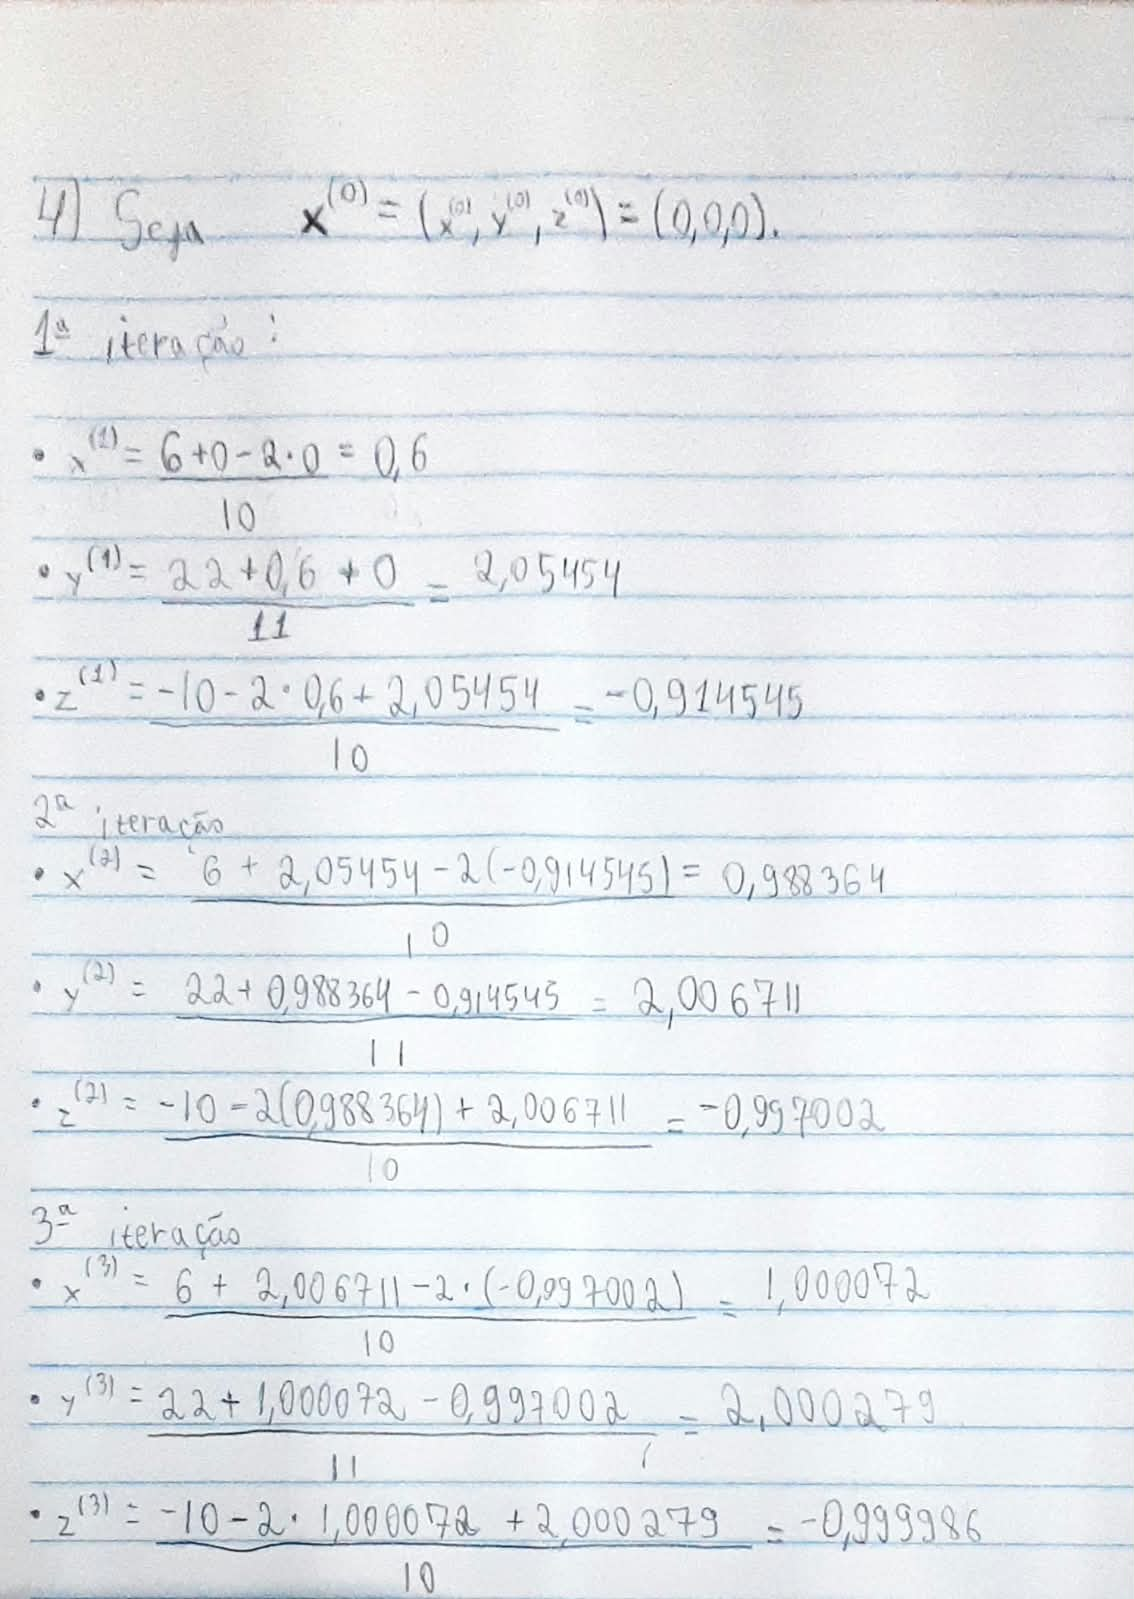

## Questão 5

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

A = np.array(
    [[10, -1, 2],
    [-1, 11, -1],
    [2, -1, 10]], dtype=float)
b = np.array([6, 22, -10], dtype=float)

def gauss_seidel(A, b, x0, tol=1e-5, max_iter=1000):
    n = len(b)
    x = x0.astype(float).copy()
    historico = [(0, *x, np.nan)]
    for k in range(1, max_iter + 1):
        x_old = x.copy()
        for i in range(n):
            soma = sum(A[i, j] * x[j] for j in range(n) if j != i)
            x[i] = (b[i] - soma) / A[i, i]
        erro = np.max(np.abs(x - x_old))
        historico.append((k, *x, erro))
        if erro < tol:
            break
    return x, k, historico

x_sol, n_iter, hist = gauss_seidel(A, b, np.zeros(3))
print("Número de iterações:", n_iter)
print("Solução aproximada: x = %.8f, y = %.8f, z = %.8f" % tuple(x_sol))
print("Solução exata (numpy):", np.linalg.solve(A, b))

Número de iterações: 6
Solução aproximada: x = 1.00000003, y = 1.99999998, z = -1.00000001
Solução exata (numpy): [ 1.  2. -1.]


## Questão 6

In [2]:
df = pd.DataFrame(hist, columns=["k", "x(k)", "y(k)", "z(k)", "||x(k)-x(k-1)||_inf"])
df["k"] = df["k"].astype(int)
df

,k,x(k),y(k),z(k),||x(k)-x(k-1)||_inf
0,0,0.000000,0.000000,0.000000,NaN
1,1,0.600000,2.054545,-0.914545,2.054545
2,2,0.988364,2.006711,-0.997002,0.388364
3,3,1.000071,2.000279,-0.999986,0.011708
4,4,1.000025,2.000004,-1.000005,0.000276
5,5,1.000001,2.000000,-1.000000,0.000024
6,6,1.000000,2.000000,-1.000000,0.000001


## Questão 7

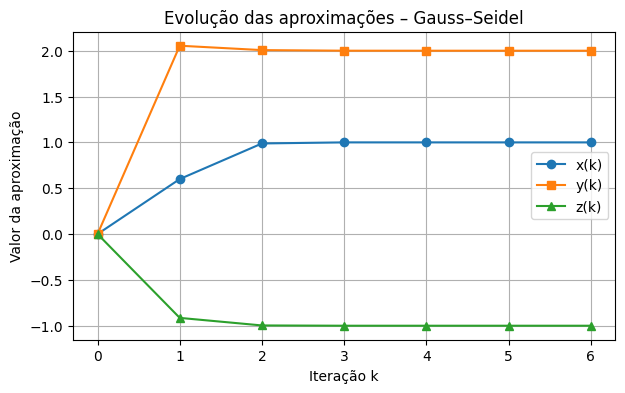

In [3]:
plt.figure(figsize=(7, 4))
plt.plot(df["k"], df["x(k)"], "o-", label="x(k)")
plt.plot(df["k"], df["y(k)"], "s-", label="y(k)")
plt.plot(df["k"], df["z(k)"], "^-", label="z(k)")
plt.xlabel("Iteração k")
plt.ylabel("Valor da aproximação")
plt.title("Evolução das aproximações – Gauss–Seidel")
plt.grid(True)
plt.legend()
plt.show()

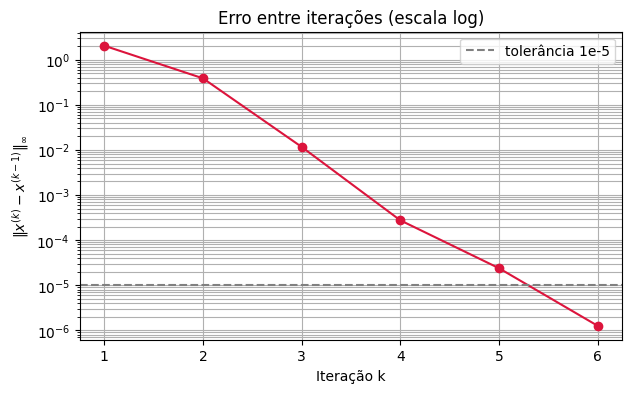

In [4]:
d = df.dropna()
plt.figure(figsize=(7, 4))
plt.semilogy(d["k"], d["||x(k)-x(k-1)||_inf"], "o-", color="crimson")
plt.axhline(1e-5, color="gray", linestyle="--", label="tolerância 1e-5")
plt.xlabel("Iteração k")
plt.ylabel(r"$\|x^{(k)}-x^{(k-1)}\|_\infty$")
plt.title("Erro entre iterações (escala log)")
plt.grid(True, which="both")
plt.legend()
plt.show()